# KL-Divergence and Perron–Doob Bandwidth Experiments

This notebook investigates whether directed Kullback–Leibler divergences between Gaussian KDEs can be converted into a spectral bandwidth selector. It studies KL asymmetry, Monte Carlo estimation of the directed KL matrix, the Perron–Doob construction, comparison with a Gaussian MISE oracle, and sensitivity to the similarity scale $\tau$.

The earlier experiments showing why a raw distance matrix selects boundary points have been moved to the archived notebook [`distance_matrix_perron_vector_tests.ipynb`](../old%20code/distance_matrix_perron_vector_tests.ipynb).


## 1. KL asymmetry sanity check

First estimate both $\mathrm{KL}(\hat f_{0.2}\,\|\,\hat f_{0.5})$ and its reverse to verify numerically that the KDE divergence is directed.


In [1]:
from __future__ import annotations

import numpy as np
from numpy.typing import ArrayLike
from scipy.special import logsumexp
from kde_tools.bandwidths import bandwidth_grid_linear_in_psi_beta


def log_gaussian_kde(
    evaluation_points: ArrayLike,
    data: ArrayLike,
    bandwidth: float,
    batch_size: int = 10_000,
) -> np.ndarray:
    """
    Evaluate the log-density of a one-dimensional Gaussian KDE.

    The KDE is

        f_h(x) = (1 / n) * sum_i N(x | X_i, h^2).

    Parameters
    ----------
    evaluation_points:
        Points at which the KDE is evaluated.
    data:
        One-dimensional sample used to construct the KDE.
    bandwidth:
        Positive Gaussian bandwidth h.
    batch_size:
        Number of evaluation points processed simultaneously.

    Returns
    -------
    np.ndarray
        Log-KDE values at the evaluation points.
    """
    x = np.asarray(evaluation_points, dtype=float).reshape(-1)
    sample = np.asarray(data, dtype=float).reshape(-1)

    if sample.size == 0:
        raise ValueError("data must contain at least one observation.")
    if bandwidth <= 0:
        raise ValueError("bandwidth must be strictly positive.")
    if batch_size <= 0:
        raise ValueError("batch_size must be strictly positive.")

    n = sample.size
    normalizing_constant = (
        -np.log(n)
        - np.log(bandwidth)
        - 0.5 * np.log(2.0 * np.pi)
    )

    result = np.empty(x.size, dtype=float)

    for start in range(0, x.size, batch_size):
        stop = min(start + batch_size, x.size)

        # Shape: (number of evaluation points in batch, sample size)
        standardized_differences = (
            x[start:stop, None] - sample[None, :]
        ) / bandwidth

        log_kernel_values = -0.5 * standardized_differences**2

        result[start:stop] = (
            normalizing_constant
            + logsumexp(log_kernel_values, axis=1)
        )

    return result


def kl_between_gaussian_kdes_mc(
    data: ArrayLike,
    bandwidth_p: float,
    bandwidth_q: float,
    n_simulations: int = 100_000,
    random_state: int | np.random.Generator | None = None,
    batch_size: int = 10_000,
) -> dict[str, float]:
    """
    Estimate KL(f_{h_p} || f_{h_q}) by Monte Carlo simulation.

    Both KDEs are constructed from the same data but use different
    Gaussian bandwidths.

    A draw from f_{h_p} is generated by:
        1. selecting one observation X_I uniformly,
        2. drawing Z ~ N(0, 1),
        3. setting Y = X_I + h_p Z.

    Then

        KL(f_{h_p} || f_{h_q})
        = E_{Y ~ f_{h_p}}[
              log f_{h_p}(Y) - log f_{h_q}(Y)
          ].

    Parameters
    ----------
    data:
        One-dimensional sample.
    bandwidth_p:
        Bandwidth of the KDE in the first KL argument.
    bandwidth_q:
        Bandwidth of the KDE in the second KL argument.
    n_simulations:
        Number of Monte Carlo samples.
    random_state:
        Integer seed, NumPy Generator, or None.
    batch_size:
        Batch size used when evaluating log-KDEs.

    Returns
    -------
    dict
        Dictionary containing the KL estimate, Monte Carlo standard error,
        and an approximate 95% confidence interval.
    """
    sample = np.asarray(data, dtype=float).reshape(-1)

    if sample.size == 0:
        raise ValueError("data must contain at least one observation.")
    if bandwidth_p <= 0 or bandwidth_q <= 0:
        raise ValueError("Both bandwidths must be strictly positive.")
    if n_simulations <= 1:
        raise ValueError("n_simulations must be greater than 1.")

    if isinstance(random_state, np.random.Generator):
        rng = random_state
    else:
        rng = np.random.default_rng(random_state)

    component_indices = rng.integers(
        low=0,
        high=sample.size,
        size=n_simulations,
    )

    simulated_points = (
        sample[component_indices]
        + bandwidth_p * rng.standard_normal(n_simulations)
    )

    log_p = log_gaussian_kde(
        evaluation_points=simulated_points,
        data=sample,
        bandwidth=bandwidth_p,
        batch_size=batch_size,
    )

    log_q = log_gaussian_kde(
        evaluation_points=simulated_points,
        data=sample,
        bandwidth=bandwidth_q,
        batch_size=batch_size,
    )

    log_density_ratio = log_p - log_q

    estimate = float(np.mean(log_density_ratio))
    standard_error = float(
        np.std(log_density_ratio, ddof=1)
        / np.sqrt(n_simulations)
    )

    confidence_radius = 1.96 * standard_error

    return {
        "estimate": estimate,
        "standard_error": standard_error,
        "ci_lower_95": estimate - confidence_radius,
        "ci_upper_95": estimate + confidence_radius,
    }

In [2]:
rng = np.random.default_rng(42)
data = rng.normal(loc=0.0, scale=1.0, size=200)

kl_02_05 = kl_between_gaussian_kdes_mc(
    data=data,
    bandwidth_p=0.2,
    bandwidth_q=0.5,
    n_simulations=100_000,
    random_state=123,
)

kl_05_02 = kl_between_gaussian_kdes_mc(
    data=data,
    bandwidth_p=0.5,
    bandwidth_q=0.2,
    n_simulations=100_000,
    random_state=456,
)

print("KL(f_0.2 || f_0.5):", kl_02_05)
print("KL(f_0.5 || f_0.2):", kl_05_02)

KL(f_0.2 || f_0.5): {'estimate': 0.018508549495929602, 'standard_error': 0.0005157362772370537, 'ci_lower_95': 0.017497706392544977, 'ci_upper_95': 0.019519392599314227}
KL(f_0.5 || f_0.2): {'estimate': 0.03862588674798749, 'standard_error': 0.0015290790948738451, 'ci_lower_95': 0.035628891722034754, 'ci_upper_95': 0.041622881773940225}


## 2. Small directed KL matrix

Construct a small bandwidth-by-bandwidth KL matrix before moving to the full experiment. Entry $(i,j)$ estimates $\mathrm{KL}(\hat f_{h_i}\,\|\,\hat f_{h_j})$.


In [3]:
def kl_kde_matrix_mc(
    data: ArrayLike,
    bandwidths: ArrayLike,
    n_simulations: int = 50_000,
    random_state: int | None = None,
    batch_size: int = 10_000,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Estimate the directed KL matrix for Gaussian KDEs.

    Returns
    -------
    kl_matrix:
        Entry (i, j) estimates KL(f_{h_i} || f_{h_j}).
    standard_errors:
        Monte Carlo standard errors for the corresponding entries.
    """
    bandwidths = np.asarray(bandwidths, dtype=float).reshape(-1)

    if np.any(bandwidths <= 0):
        raise ValueError("All bandwidths must be strictly positive.")

    rng = np.random.default_rng(random_state)
    m = bandwidths.size

    kl_matrix = np.zeros((m, m), dtype=float)
    standard_errors = np.zeros((m, m), dtype=float)

    for i, h_p in enumerate(bandwidths):
        # Reuse one Monte Carlo sample from the i-th KDE for all j.
        sample = np.asarray(data, dtype=float).reshape(-1)
        component_indices = rng.integers(
            0, sample.size, size=n_simulations
        )
        simulated_points = (
            sample[component_indices]
            + h_p * rng.standard_normal(n_simulations)
        )

        log_p = log_gaussian_kde(
            simulated_points,
            sample,
            h_p,
            batch_size=batch_size,
        )

        for j, h_q in enumerate(bandwidths):
            if i == j:
                continue

            log_q = log_gaussian_kde(
                simulated_points,
                sample,
                h_q,
                batch_size=batch_size,
            )

            log_ratio = log_p - log_q

            kl_matrix[i, j] = np.mean(log_ratio)
            standard_errors[i, j] = (
                np.std(log_ratio, ddof=1)
                / np.sqrt(n_simulations)
            )

    return kl_matrix, standard_errors

In [4]:
bandwidths = bandwidth_grid_linear_in_psi_beta(
    h_min=0.1,
    h_max=0.8,
    beta=2.0,
    grid_size=4,
)

kl_matrix, se_matrix = kl_kde_matrix_mc(
    data=data,
    bandwidths=bandwidths,
    n_simulations=50_000,
    random_state=123,
)

print(kl_matrix)

[[0.         0.01185886 0.03086599 0.10180191]
 [0.01719789 0.         0.00946458 0.07528969]
 [0.09379205 0.01638851 0.         0.03964042]
 [0.83656703 0.23566098 0.06777679 0.        ]]


## 3. Full KL matrix and population benchmark

Estimate the directed KL matrix on a larger bandwidth grid, report Monte Carlo diagnostics, and compare it with the analytic KL matrix for the corresponding Gaussian-smoothed population densities.


First bandwidth: 0.010538589185454863
Last bandwidth: 1.897787232052236
Number of bandwidths: 100
Completed row 1 of 100
Completed row 10 of 100
Completed row 20 of 100
Completed row 30 of 100
Completed row 40 of 100
Completed row 50 of 100
Completed row 60 of 100
Completed row 70 of 100
Completed row 80 of 100
Completed row 90 of 100
Completed row 100 of 100
Smallest raw off-diagonal estimate: nan
Maximum Monte Carlo standard error: 191.8879306917087
Maximum asymmetry |D_ij - D_ji|: 1499.0486388967904


/var/folders/tr/kt47kz8d61ngpcfl5d_s9fc80000gn/T/ipykernel_3666/617306853.py:374: RuntimeWarning: invalid value encountered in multiply
  + np.eye(N_BANDWIDTHS) * np.inf


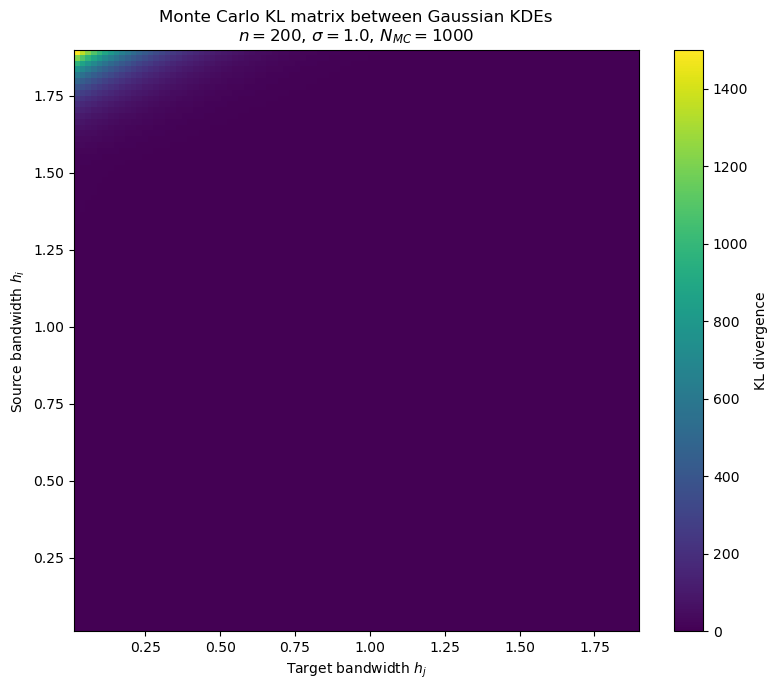

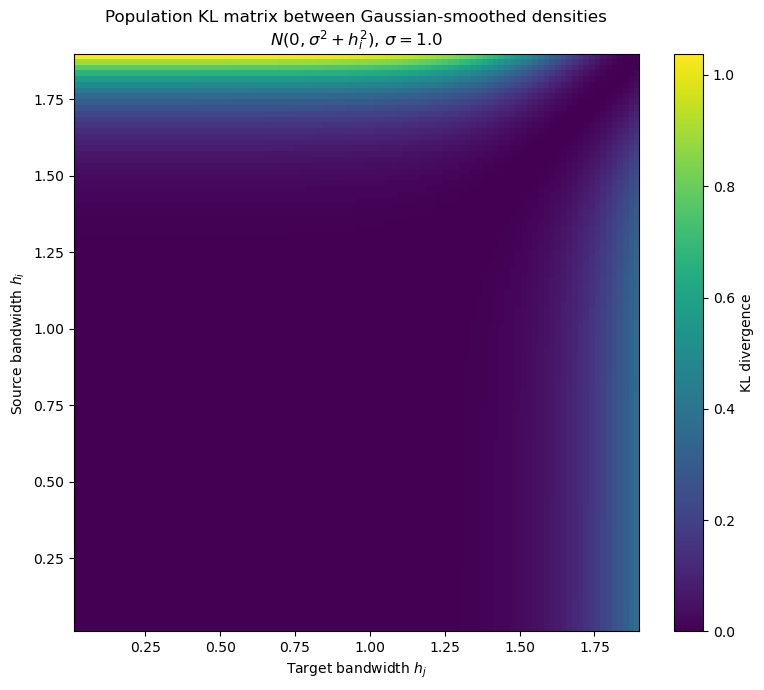

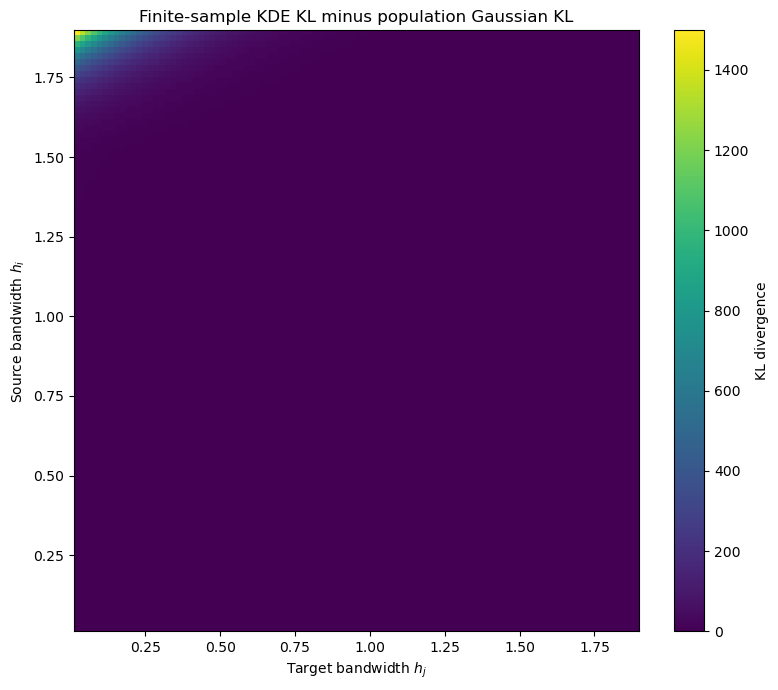

In [5]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
from numpy.typing import ArrayLike
from scipy.special import logsumexp

from kde_tools.bandwidths import bandwidth_grid_linear_in_psi_beta


def log_gaussian_kdes(
    evaluation_points: ArrayLike,
    data: ArrayLike,
    bandwidths: ArrayLike,
    point_batch_size: int = 256,
    bandwidth_batch_size: int = 10,
) -> np.ndarray:
    """
    Evaluate several one-dimensional Gaussian KDEs at the same points.

    For bandwidth h_j,

        f_hat_hj(x)
        =
        (1 / n) sum_k phi_hj(x - X_k).

    Parameters
    ----------
    evaluation_points:
        Points x at which all KDEs are evaluated.
    data:
        One-dimensional data sample.
    bandwidths:
        Positive KDE bandwidths.
    point_batch_size:
        Number of evaluation points handled simultaneously.
    bandwidth_batch_size:
        Number of bandwidths handled simultaneously.

    Returns
    -------
    log_densities:
        Array of shape (number of evaluation points, number of bandwidths).
        Entry (m, j) is log f_hat_{h_j}(evaluation_points[m]).
    """
    points = np.asarray(evaluation_points, dtype=float).reshape(-1)
    sample = np.asarray(data, dtype=float).reshape(-1)
    hs = np.asarray(bandwidths, dtype=float).reshape(-1)

    if sample.size == 0:
        raise ValueError("data must contain at least one observation.")

    if np.any(hs <= 0):
        raise ValueError("All bandwidths must be strictly positive.")

    if point_batch_size <= 0 or bandwidth_batch_size <= 0:
        raise ValueError("Batch sizes must be strictly positive.")

    number_of_points = points.size
    number_of_bandwidths = hs.size
    sample_size = sample.size

    result = np.empty(
        (number_of_points, number_of_bandwidths),
        dtype=float,
    )

    constants = (
        -np.log(sample_size)
        - np.log(hs)
        - 0.5 * np.log(2.0 * np.pi)
    )

    for point_start in range(0, number_of_points, point_batch_size):
        point_stop = min(
            point_start + point_batch_size,
            number_of_points,
        )

        point_chunk = points[point_start:point_stop]

        # Shape: (point batch size, sample size)
        squared_distances = (
            point_chunk[:, None] - sample[None, :]
        ) ** 2

        for bandwidth_start in range(
            0,
            number_of_bandwidths,
            bandwidth_batch_size,
        ):
            bandwidth_stop = min(
                bandwidth_start + bandwidth_batch_size,
                number_of_bandwidths,
            )

            bandwidth_chunk = hs[bandwidth_start:bandwidth_stop]

            # Shape:
            # (point batch size, bandwidth batch size, sample size)
            log_kernel_values = (
                -squared_distances[:, None, :]
                / (
                    2.0
                    * bandwidth_chunk[None, :, None] ** 2
                )
            )

            result[
                point_start:point_stop,
                bandwidth_start:bandwidth_stop,
            ] = (
                constants[None, bandwidth_start:bandwidth_stop]
                + logsumexp(log_kernel_values, axis=2)
            )

    return result


def gaussian_kde_kl_matrix_mc(
    data: ArrayLike,
    bandwidths: ArrayLike,
    n_mc: int = 1_000,
    random_state: int | None = None,
    point_batch_size: int = 256,
    bandwidth_batch_size: int = 10,
    show_progress: bool = True,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Estimate the directed KL matrix between Gaussian KDEs.

    Entry (i, j) estimates

        KL(f_hat_{h_i} || f_hat_{h_j}).

    For each source KDE f_hat_{h_i}, draws are generated as

        Y = X_I + h_i Z,

    where I is uniform on {1, ..., n} and Z ~ N(0, 1).

    Parameters
    ----------
    data:
        One-dimensional sample.
    bandwidths:
        Positive KDE bandwidths.
    n_mc:
        Number of Monte Carlo draws per source bandwidth.
    random_state:
        Random seed.
    point_batch_size:
        Point batching used during KDE evaluation.
    bandwidth_batch_size:
        Bandwidth batching used during KDE evaluation.
    show_progress:
        Print progress information.

    Returns
    -------
    kl_matrix:
        Directed KL matrix.
    standard_error_matrix:
        Monte Carlo standard error for every entry.
    """
    sample = np.asarray(data, dtype=float).reshape(-1)
    hs = np.asarray(bandwidths, dtype=float).reshape(-1)

    if sample.size == 0:
        raise ValueError("data must contain at least one observation.")

    if np.any(hs <= 0):
        raise ValueError("All bandwidths must be strictly positive.")

    if n_mc <= 1:
        raise ValueError("n_mc must be greater than 1.")

    rng = np.random.default_rng(random_state)

    number_of_bandwidths = hs.size
    sample_size = sample.size

    kl_matrix = np.zeros(
        (number_of_bandwidths, number_of_bandwidths),
        dtype=float,
    )

    standard_error_matrix = np.zeros_like(kl_matrix)

    # Common random numbers across rows.
    # For each h_i, X_I + h_i Z still has exactly the correct KDE law.
    component_indices = rng.integers(
        low=0,
        high=sample_size,
        size=n_mc,
    )
    standard_normals = rng.standard_normal(n_mc)

    for i, source_bandwidth in enumerate(hs):
        simulated_points = (
            sample[component_indices]
            + source_bandwidth * standard_normals
        )

        # log_densities[m, j]
        # = log f_hat_{h_j}(simulated_points[m])
        log_densities = log_gaussian_kdes(
            evaluation_points=simulated_points,
            data=sample,
            bandwidths=hs,
            point_batch_size=point_batch_size,
            bandwidth_batch_size=bandwidth_batch_size,
        )

        source_log_density = log_densities[:, i]

        # Each column j contains
        # log f_hat_{h_i}(Y_m) - log f_hat_{h_j}(Y_m).
        log_ratios = (
            source_log_density[:, None] - log_densities
        )

        kl_matrix[i, :] = np.mean(log_ratios, axis=0)

        standard_error_matrix[i, :] = (
            np.std(log_ratios, axis=0, ddof=1)
            / np.sqrt(n_mc)
        )

        # The diagonal is mathematically exactly zero.
        kl_matrix[i, i] = 0.0
        standard_error_matrix[i, i] = 0.0

        if show_progress and (
            i == 0
            or (i + 1) % 10 == 0
            or i + 1 == number_of_bandwidths
        ):
            print(
                f"Completed row {i + 1}"
                f" of {number_of_bandwidths}"
            )

    return kl_matrix, standard_error_matrix


def population_gaussian_kl_matrix(
    bandwidths: ArrayLike,
    sigma: float,
) -> np.ndarray:
    """
    Population comparison matrix for Gaussian-smoothed N(0, sigma^2).

    If

        f = N(0, sigma^2),

    then

        f * phi_h = N(0, sigma^2 + h^2).

    Entry (i, j) is

        KL(
            N(0, sigma^2 + h_i^2)
            ||
            N(0, sigma^2 + h_j^2)
        ).
    """
    hs = np.asarray(bandwidths, dtype=float).reshape(-1)

    if sigma <= 0:
        raise ValueError("sigma must be strictly positive.")

    variances = sigma**2 + hs**2

    variance_i = variances[:, None]
    variance_j = variances[None, :]

    matrix = 0.5 * (
        variance_i / variance_j
        - 1.0
        + np.log(variance_j / variance_i)
    )

    np.fill_diagonal(matrix, 0.0)
    return matrix


def plot_matrix(
    matrix: np.ndarray,
    bandwidths: np.ndarray,
    title: str,
) -> None:
    """Plot a bandwidth-by-bandwidth matrix."""
    plt.figure(figsize=(8, 7))

    image = plt.imshow(
        matrix,
        origin="lower",
        aspect="auto",
        extent=[
            bandwidths[0],
            bandwidths[-1],
            bandwidths[0],
            bandwidths[-1],
        ],
    )

    plt.colorbar(image, label="KL divergence")
    plt.xlabel(r"Target bandwidth $h_j$")
    plt.ylabel(r"Source bandwidth $h_i$")
    plt.title(title)
    plt.tight_layout()
    plt.show()


# ============================================================
# Experiment
# ============================================================

SEED = 12345

# Data distribution
SIGMA = 1.0
N_DATA = 200

# Bandwidth grid
N_BANDWIDTHS = 100
H_MIN = 0.01
H_MAX = 2.0

# Number of Monte Carlo points for every matrix row.
# Increase this later for greater precision.
N_MC = 1_000

rng = np.random.default_rng(SEED)

# Sample X_1, ..., X_n ~ N(0, sigma^2)
data = rng.normal(
    loc=0.0,
    scale=SIGMA,
    size=N_DATA,
)

# Exactly 100 geometrically spaced interior points of (0.01, 2).
# The endpoints 0.01 and 2 are excluded.
bandwidths = bandwidth_grid_linear_in_psi_beta(
    h_min=H_MIN,
    h_max=H_MAX,
    beta=2.0,
    grid_size=N_BANDWIDTHS + 2,
)[1:-1]

print("First bandwidth:", bandwidths[0])
print("Last bandwidth:", bandwidths[-1])
print("Number of bandwidths:", bandwidths.size)

kl_matrix_mc, kl_standard_errors = gaussian_kde_kl_matrix_mc(
    data=data,
    bandwidths=bandwidths,
    n_mc=N_MC,
    random_state=SEED + 1,
    point_batch_size=256,
    bandwidth_batch_size=10,
    show_progress=True,
)

# Small negative values can occur because of Monte Carlo error.
print(
    "Smallest raw off-diagonal estimate:",
    np.min(
        kl_matrix_mc
        + np.eye(N_BANDWIDTHS) * np.inf
    ),
)

print(
    "Maximum Monte Carlo standard error:",
    np.max(kl_standard_errors),
)

print(
    "Maximum asymmetry |D_ij - D_ji|:",
    np.max(np.abs(kl_matrix_mc - kl_matrix_mc.T)),
)

plot_matrix(
    matrix=kl_matrix_mc,
    bandwidths=bandwidths,
    title=(
        "Monte Carlo KL matrix between Gaussian KDEs\n"
        rf"$n={N_DATA}$, $\sigma={SIGMA}$, "
        rf"$N_{{MC}}={N_MC}$"
    ),
)

# Population benchmark
kl_matrix_population = population_gaussian_kl_matrix(
    bandwidths=bandwidths,
    sigma=SIGMA,
)

plot_matrix(
    matrix=kl_matrix_population,
    bandwidths=bandwidths,
    title=(
        "Population KL matrix between Gaussian-smoothed densities\n"
        rf"$N(0,\sigma^2+h_i^2)$, $\sigma={SIGMA}$"
    ),
)

# Difference between the finite-sample KDE matrix and population matrix
plot_matrix(
    matrix=kl_matrix_mc - kl_matrix_population,
    bandwidths=bandwidths,
    title="Finite-sample KDE KL minus population Gaussian KL",
)

# Save results
np.savetxt(
    "outputs/csv/08_kl_distance_matrices/bandwidths.csv",
    bandwidths,
    delimiter=",",
)

np.savetxt(
    "outputs/csv/08_kl_distance_matrices/kl_matrix_mc.csv",
    kl_matrix_mc,
    delimiter=",",
)

np.savetxt(
    "outputs/csv/08_kl_distance_matrices/kl_standard_errors.csv",
    kl_standard_errors,
    delimiter=",",
)

np.savetxt(
    "outputs/csv/08_kl_distance_matrices/kl_matrix_population.csv",
    kl_matrix_population,
    delimiter=",",
)


## 4. Perron–Doob construction

Convert the directed divergence matrix into the positive similarity matrix $S_{ij}=\exp(-D_{ij}/\tau)$. The left and right Perron vectors define a Doob-transformed Markov chain whose stationary distribution supplies the bandwidth score.


Similarity scale tau: 0.12859549
Perron eigenvalue: 48.623113
Left/right eigenvalue difference: 7.105e-14
Maximum transition row-sum error: 2.220e-16
Maximum stationarity error: 1.018e-15


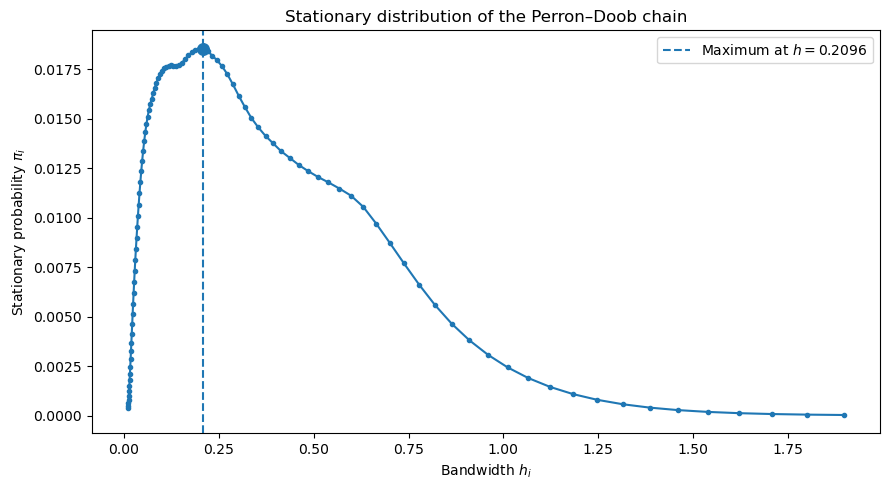

Selected index: 57
Selected bandwidth: 0.2095962759081172
Stationary probability: 0.01853510874684457


In [6]:
import numpy as np
import matplotlib.pyplot as plt


def positive_perron_vector(
    matrix: np.ndarray,
    tolerance: float = 1e-13,
    max_iterations: int = 100_000,
) -> tuple[float, np.ndarray]:
    """
    Compute the positive right Perron vector by power iteration.

    Returns
    -------
    eigenvalue:
        Perron eigenvalue.
    eigenvector:
        Positive Perron vector normalized to have sum 1.
    """
    matrix = np.asarray(matrix, dtype=float)

    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError("matrix must be square.")

    if np.any(matrix < 0):
        raise ValueError("matrix must be nonnegative.")

    n = matrix.shape[0]
    vector = np.full(n, 1.0 / n)

    for _ in range(max_iterations):
        new_vector = matrix @ vector

        normalization = np.sum(new_vector)

        if normalization <= 0 or not np.isfinite(normalization):
            raise RuntimeError(
                "Power iteration encountered an invalid normalization."
            )

        new_vector /= normalization

        if np.linalg.norm(new_vector - vector, ord=1) < tolerance:
            vector = new_vector
            break

        vector = new_vector
    else:
        raise RuntimeError("Power iteration did not converge.")

    # Rayleigh quotient
    eigenvalue = float(
        vector @ (matrix @ vector)
        / (vector @ vector)
    )

    return eigenvalue, vector


def doob_transform_from_divergence(
    divergence_matrix: np.ndarray,
    tau: float | None = None,
) -> dict[str, np.ndarray | float]:
    """
    Transform a directed divergence matrix into a similarity matrix,
    compute the left/right Perron vectors, the Doob transform, and its
    stationary distribution.

    Parameters
    ----------
    divergence_matrix:
        Matrix D with D[i, j] representing the directed divergence
        from state i to state j.
    tau:
        Similarity scale in

            S[i, j] = exp(-D[i, j] / tau).

        If None, the median positive off-diagonal divergence is used.

    Returns
    -------
    Dictionary containing:
        divergence_matrix
        similarity_matrix
        tau
        perron_eigenvalue
        right_perron_vector
        left_perron_vector
        transition_matrix
        stationary_distribution
    """
    D = np.asarray(divergence_matrix, dtype=float).copy()

    if D.ndim != 2 or D.shape[0] != D.shape[1]:
        raise ValueError("divergence_matrix must be square.")

    if not np.all(np.isfinite(D)):
        raise ValueError("The divergence matrix contains non-finite values.")

    # Monte Carlo estimates can occasionally be slightly negative.
    D = np.maximum(D, 0.0)
    np.fill_diagonal(D, 0.0)

    n = D.shape[0]
    off_diagonal_mask = ~np.eye(n, dtype=bool)
    positive_off_diagonal = D[
        off_diagonal_mask & (D > 0)
    ]

    if tau is None:
        if positive_off_diagonal.size == 0:
            raise ValueError(
                "Cannot determine tau because all divergences are zero."
            )

        tau = float(np.median(positive_off_diagonal))

    if tau <= 0 or not np.isfinite(tau):
        raise ValueError("tau must be finite and strictly positive.")

    # Directed positive similarity matrix
    S = np.exp(-D / tau)

    # Right Perron vector: S r = rho r
    rho_right, right = positive_perron_vector(S)

    # Left Perron vector: S^T ell = rho ell
    rho_left, left = positive_perron_vector(S.T)

    # Use a bilinear estimate of the common Perron eigenvalue.
    rho = float(
        left @ (S @ right)
        / (left @ right)
    )

    # Doob transform:
    #
    # P_ij = S_ij r_j / (rho r_i)
    P = (
        S
        * right[None, :]
        / (rho * right[:, None])
    )

    # Remove negligible numerical row-sum error.
    P /= P.sum(axis=1, keepdims=True)

    # Natural left-right combination
    stationary = left * right
    stationary /= stationary.sum()

    # Diagnostics
    row_sum_error = np.max(
        np.abs(P.sum(axis=1) - 1.0)
    )

    stationarity_error = np.max(
        np.abs(stationary @ P - stationary)
    )

    eigenvalue_difference = abs(rho_right - rho_left)

    print(f"Similarity scale tau: {tau:.8g}")
    print(f"Perron eigenvalue: {rho:.8g}")
    print(
        "Left/right eigenvalue difference:",
        f"{eigenvalue_difference:.3e}",
    )
    print(
        "Maximum transition row-sum error:",
        f"{row_sum_error:.3e}",
    )
    print(
        "Maximum stationarity error:",
        f"{stationarity_error:.3e}",
    )

    return {
        "divergence_matrix": D,
        "similarity_matrix": S,
        "tau": tau,
        "perron_eigenvalue": rho,
        "right_perron_vector": right,
        "left_perron_vector": left,
        "transition_matrix": P,
        "stationary_distribution": stationary,
    }


def plot_stationary_distribution(
    bandwidths: np.ndarray,
    stationary_distribution: np.ndarray,
) -> None:
    """Plot the stationary probability assigned to each bandwidth."""
    bandwidths = np.asarray(bandwidths, dtype=float)
    stationary_distribution = np.asarray(
        stationary_distribution,
        dtype=float,
    )

    critical_index = int(np.argmax(stationary_distribution))
    critical_bandwidth = bandwidths[critical_index]
    critical_probability = stationary_distribution[critical_index]

    plt.figure(figsize=(9, 5))

    plt.plot(
        bandwidths,
        stationary_distribution,
        marker="o",
        markersize=3,
        linewidth=1.5,
    )

    plt.axvline(
        critical_bandwidth,
        linestyle="--",
        label=(
            rf"Maximum at $h={critical_bandwidth:.4f}$"
        ),
    )

    plt.scatter(
        [critical_bandwidth],
        [critical_probability],
        s=70,
        zorder=3,
    )

    plt.xlabel(r"Bandwidth $h_i$")
    plt.ylabel(r"Stationary probability $\pi_i$")
    plt.title(
        "Stationary distribution of the Perron–Doob chain"
    )
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("Selected index:", critical_index)
    print("Selected bandwidth:", critical_bandwidth)
    print("Stationary probability:", critical_probability)


# ============================================================
# Apply to the previously calculated KL matrix
# ============================================================

doob_result = doob_transform_from_divergence(
    divergence_matrix=kl_matrix_mc,
    tau=None,
)

stationary_distribution = doob_result[
    "stationary_distribution"
]

transition_matrix = doob_result["transition_matrix"]
similarity_matrix = doob_result["similarity_matrix"]
left_perron = doob_result["left_perron_vector"]
right_perron = doob_result["right_perron_vector"]

plot_stationary_distribution(
    bandwidths=bandwidths,
    stationary_distribution=stationary_distribution,
)

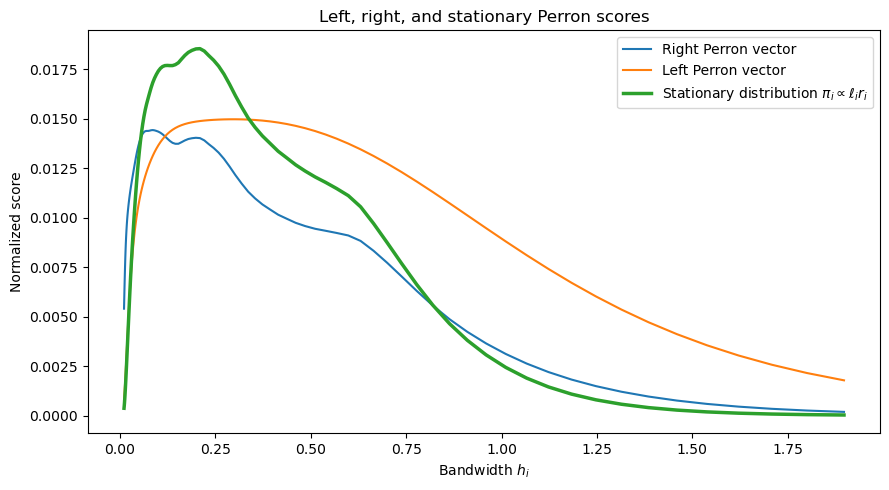

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(
    bandwidths,
    right_perron / right_perron.sum(),
    label="Right Perron vector",
)

plt.plot(
    bandwidths,
    left_perron / left_perron.sum(),
    label="Left Perron vector",
)

plt.plot(
    bandwidths,
    stationary_distribution,
    linewidth=2.5,
    label=r"Stationary distribution $\pi_i \propto \ell_i r_i$",
)

plt.xlabel(r"Bandwidth $h_i$")
plt.ylabel("Normalized score")
plt.title("Left, right, and stationary Perron scores")
plt.legend()
plt.tight_layout()
plt.show()

## 5. End-to-end selector and oracle comparison

This exploratory block contains an alternative end-to-end implementation and compares its selected KDE with the exact Gaussian MISE oracle. It is retained as a prototype for further consolidation.


In [8]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import logsumexp
from scipy.optimize import minimize_scalar
from scipy.stats import norm


# ============================================================
# Gaussian KDE evaluation
# ============================================================

def gaussian_kde_density(x, data, bandwidth):
    """Evaluate a one-dimensional Gaussian KDE."""
    x = np.asarray(x, dtype=float).reshape(-1)
    data = np.asarray(data, dtype=float).reshape(-1)

    if bandwidth <= 0:
        raise ValueError("bandwidth must be positive")

    z = (x[:, None] - data[None, :]) / bandwidth
    return np.mean(norm.pdf(z), axis=1) / bandwidth


def log_gaussian_kdes(
    evaluation_points,
    data,
    bandwidths,
    point_batch_size=500,
):
    """
    Evaluate log KDEs for several bandwidths.

    Returns an array with shape
        (number of evaluation points, number of bandwidths).
    """
    points = np.asarray(evaluation_points, dtype=float).reshape(-1)
    data = np.asarray(data, dtype=float).reshape(-1)
    bandwidths = np.asarray(bandwidths, dtype=float).reshape(-1)

    if np.any(bandwidths <= 0):
        raise ValueError("All bandwidths must be positive")

    n_points = len(points)
    n_bandwidths = len(bandwidths)
    n_data = len(data)

    result = np.empty((n_points, n_bandwidths))

    constants = (
        -np.log(n_data)
        - np.log(bandwidths)
        - 0.5 * np.log(2.0 * np.pi)
    )

    for start in range(0, n_points, point_batch_size):
        stop = min(start + point_batch_size, n_points)

        differences_squared = (
            points[start:stop, None] - data[None, :]
        ) ** 2

        for j, h in enumerate(bandwidths):
            log_kernel_values = (
                -differences_squared / (2.0 * h**2)
            )

            result[start:stop, j] = (
                constants[j]
                + logsumexp(log_kernel_values, axis=1)
            )

    return result


# ============================================================
# Monte Carlo KL matrix
# ============================================================

def gaussian_kde_kl_matrix_mc(
    data,
    bandwidths,
    n_mc=2000,
    random_state=None,
    show_progress=True,
):
    """
    Estimate

        D[i,j] = KL(f_hat_{h_i} || f_hat_{h_j})

    by Monte Carlo simulation.
    """
    data = np.asarray(data, dtype=float).reshape(-1)
    bandwidths = np.asarray(bandwidths, dtype=float).reshape(-1)

    rng = np.random.default_rng(random_state)

    n = len(data)
    number_of_bandwidths = len(bandwidths)

    kl_matrix = np.zeros(
        (number_of_bandwidths, number_of_bandwidths)
    )

    standard_errors = np.zeros_like(kl_matrix)

    # Common random numbers reduce simulation noise.
    component_indices = rng.integers(
        0,
        n,
        size=n_mc,
    )

    gaussian_noise = rng.standard_normal(n_mc)

    for i, h_source in enumerate(bandwidths):

        # Exact draws from the source KDE
        simulated_points = (
            data[component_indices]
            + h_source * gaussian_noise
        )

        log_densities = log_gaussian_kdes(
            evaluation_points=simulated_points,
            data=data,
            bandwidths=bandwidths,
        )

        log_source = log_densities[:, i]

        log_ratios = (
            log_source[:, None] - log_densities
        )

        kl_matrix[i, :] = np.mean(log_ratios, axis=0)

        standard_errors[i, :] = (
            np.std(log_ratios, axis=0, ddof=1)
            / np.sqrt(n_mc)
        )

        kl_matrix[i, i] = 0.0
        standard_errors[i, i] = 0.0

        if show_progress and (
            (i + 1) % 10 == 0
            or i == 0
            or i + 1 == number_of_bandwidths
        ):
            print(
                f"KL row {i + 1}/{number_of_bandwidths}"
            )

    return kl_matrix, standard_errors


# ============================================================
# Perron vectors and Doob transform
# ============================================================

def perron_eigenvector(matrix):
    """
    Return the Perron eigenvalue and a positive right eigenvector.

    The eigenvector is normalized to sum to one.
    """
    matrix = np.asarray(matrix, dtype=float)

    eigenvalues, eigenvectors = np.linalg.eig(matrix)

    perron_index = np.argmax(eigenvalues.real)

    eigenvalue = float(eigenvalues[perron_index].real)
    eigenvector = eigenvectors[:, perron_index].real

    # Resolve the arbitrary sign
    if np.sum(eigenvector) < 0:
        eigenvector = -eigenvector

    # Remove tiny numerical negative values
    eigenvector = np.maximum(eigenvector, 0.0)
    eigenvector /= np.sum(eigenvector)

    return eigenvalue, eigenvector


def doob_transform_from_divergence(
    divergence_matrix,
    tau=None,
):
    """
    Convert a divergence matrix D to

        S_ij = exp(-D_ij / tau),

    and compute the Perron–Doob Markov chain.
    """
    D = np.asarray(divergence_matrix, dtype=float).copy()

    if D.ndim != 2 or D.shape[0] != D.shape[1]:
        raise ValueError("D must be square")

    # Remove small negative Monte Carlo estimates
    D = np.maximum(D, 0.0)
    np.fill_diagonal(D, 0.0)

    n = D.shape[0]

    mask = ~np.eye(n, dtype=bool)
    positive_values = D[mask & (D > 0)]

    if tau is None:
        tau = float(np.median(positive_values))

    if tau <= 0:
        raise ValueError("tau must be positive")

    similarity_matrix = np.exp(-D / tau)

    # Right Perron vector
    rho_right, right = perron_eigenvector(
        similarity_matrix
    )

    # Left Perron vector
    rho_left, left = perron_eigenvector(
        similarity_matrix.T
    )

    # Bilinear Perron eigenvalue estimate
    rho = float(
        left @ similarity_matrix @ right
        / (left @ right)
    )

    # Doob transform
    transition_matrix = (
        similarity_matrix
        * right[None, :]
        / (rho * right[:, None])
    )

    # Natural combination of left and right Perron vectors
    stationary_distribution = left * right
    stationary_distribution /= stationary_distribution.sum()

    print(f"tau = {tau:.8f}")
    print(f"Perron eigenvalue = {rho:.8f}")

    print(
        "Maximum row-sum error:",
        np.max(
            np.abs(
                transition_matrix.sum(axis=1) - 1.0
            )
        ),
    )

    print(
        "Maximum stationarity error:",
        np.max(
            np.abs(
                stationary_distribution
                @ transition_matrix
                - stationary_distribution
            )
        ),
    )

    return {
        "divergence_matrix": D,
        "similarity_matrix": similarity_matrix,
        "transition_matrix": transition_matrix,
        "stationary_distribution": stationary_distribution,
        "right_perron_vector": right,
        "left_perron_vector": left,
        "perron_eigenvalue": rho,
        "tau": tau,
    }


def plot_stationary_distribution(
    bandwidths,
    stationary_distribution,
):
    """Plot the stationary Doob distribution."""
    bandwidths = np.asarray(bandwidths)
    stationary_distribution = np.asarray(
        stationary_distribution
    )

    selected_index = int(
        np.argmax(stationary_distribution)
    )

    selected_bandwidth = bandwidths[selected_index]

    plt.figure(figsize=(9, 5))

    plt.plot(
        bandwidths,
        stationary_distribution,
        marker="o",
        markersize=3,
    )

    plt.axvline(
        selected_bandwidth,
        linestyle="--",
        label=rf"Selected $h={selected_bandwidth:.4f}$",
    )

    plt.xlabel(r"Bandwidth $h$")
    plt.ylabel(r"Stationary probability $\pi(h)$")
    plt.title("Stationary distribution of the Doob chain")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return selected_index, selected_bandwidth


# ============================================================
# Exact Gaussian MISE and oracle bandwidth
# ============================================================

def exact_gaussian_kde_mise(
    bandwidth,
    sample_size,
    sigma,
):
    """
    Exact MISE for Gaussian data and a Gaussian kernel.
    """
    h = float(bandwidth)

    if h <= 0:
        return np.inf

    term_1 = (
        1.0
        / (
            2.0
            * np.sqrt(np.pi)
            * sample_size
            * h
        )
    )

    term_2 = (
        (1.0 - 1.0 / sample_size)
        / (
            2.0
            * np.sqrt(np.pi)
            * np.sqrt(sigma**2 + h**2)
        )
    )

    term_3 = (
        -2.0
        / np.sqrt(
            2.0
            * np.pi
            * (2.0 * sigma**2 + h**2)
        )
    )

    term_4 = (
        1.0
        / (
            2.0
            * np.sqrt(np.pi)
            * sigma
        )
    )

    return term_1 + term_2 + term_3 + term_4


def compute_gaussian_mise_oracle(
    sample_size,
    sigma,
    lower_bound=1e-5,
    upper_bound=5.0,
):
    """Find the exact continuous MISE-optimal bandwidth."""
    result = minimize_scalar(
        lambda h: exact_gaussian_kde_mise(
            h,
            sample_size,
            sigma,
        ),
        bounds=(lower_bound, upper_bound),
        method="bounded",
    )

    if not result.success:
        raise RuntimeError(result.message)

    return float(result.x), float(result.fun)


# ============================================================
# Final comparison plot
# ============================================================

def plot_kde_comparison(
    data,
    sigma,
    h_spectral,
    h_oracle,
):
    """
    Plot the true density, spectral KDE, and oracle KDE.
    """
    data = np.asarray(data)

    largest_h = max(h_spectral, h_oracle)

    x_min = min(data.min(), -5.0 * sigma) - 3 * largest_h
    x_max = max(data.max(), 5.0 * sigma) + 3 * largest_h

    x_grid = np.linspace(x_min, x_max, 4000)

    true_density = norm.pdf(
        x_grid,
        loc=0.0,
        scale=sigma,
    )

    spectral_density = gaussian_kde_density(
        x_grid,
        data,
        h_spectral,
    )

    oracle_density = gaussian_kde_density(
        x_grid,
        data,
        h_oracle,
    )

    spectral_ise = np.trapz(
        (spectral_density - true_density) ** 2,
        x=x_grid,
    )

    oracle_ise = np.trapz(
        (oracle_density - true_density) ** 2,
        x=x_grid,
    )

    plt.figure(figsize=(10, 6))

    plt.plot(
        x_grid,
        true_density,
        linewidth=2.5,
        label=rf"True $N(0,{sigma}^2)$",
    )

    plt.plot(
        x_grid,
        spectral_density,
        linewidth=2,
        label=rf"KL spectral KDE: $h={h_spectral:.4f}$",
    )

    plt.plot(
        x_grid,
        oracle_density,
        linestyle="--",
        linewidth=2,
        label=rf"MISE oracle KDE: $h={h_oracle:.4f}$",
    )

    plt.vlines(
        data,
        ymin=0,
        ymax=0.01 * true_density.max(),
        alpha=0.25,
        linewidth=0.5,
    )

    plt.xlabel(r"$x$")
    plt.ylabel("Density")
    plt.title("KL-spectral bandwidth versus MISE oracle")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"Observed spectral ISE: {spectral_ise:.10f}")
    print(f"Observed oracle ISE:   {oracle_ise:.10f}")

KL row 1/100
KL row 10/100
KL row 20/100
KL row 30/100
KL row 40/100
KL row 50/100
KL row 60/100
KL row 70/100
KL row 80/100
KL row 90/100
KL row 100/100
tau = 0.13307511
Perron eigenvalue = 48.71178282
Maximum row-sum error: 9.547918011776346e-15
Maximum stationarity error: 4.163336342344337e-17


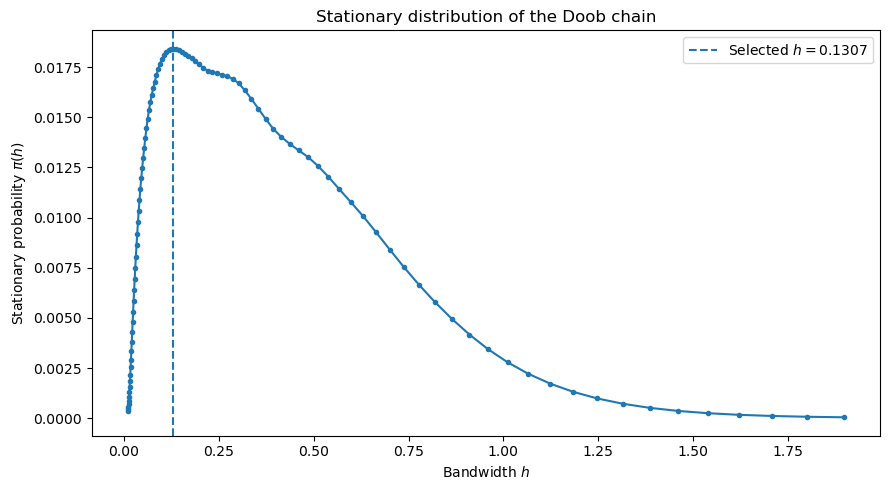

KL-spectral h: 0.13071977
MISE-oracle h: 0.38303896
Minimum MISE:  0.0033223377


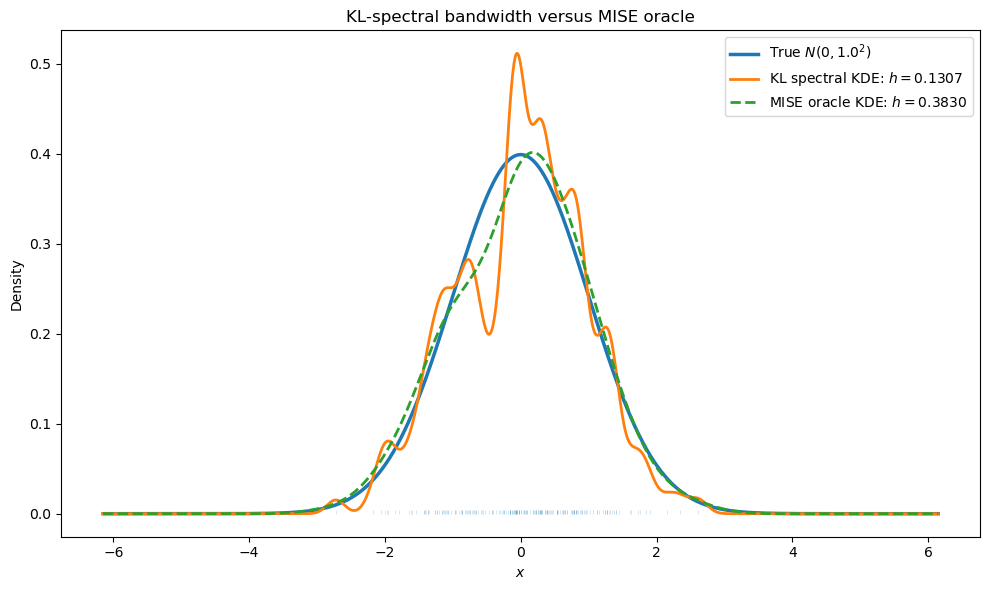

Observed spectral ISE: 0.0118311051
Observed oracle ISE:   0.0022570541


In [9]:
SEED = 12345
SIGMA = 1.0
N_DATA = 200
N_BANDWIDTHS = 100
N_MC = 2000

rng = np.random.default_rng(SEED)

data = rng.normal(
    loc=0.0,
    scale=SIGMA,
    size=N_DATA,
)

# 100 geometrically spaced interior points of (0.01, 2)
bandwidths = bandwidth_grid_linear_in_psi_beta(
    h_min=0.01,
    h_max=2.0,
    beta=2.0,
    grid_size=N_BANDWIDTHS + 2,
)[1:-1]

kl_matrix_mc, kl_standard_errors = (
    gaussian_kde_kl_matrix_mc(
        data=data,
        bandwidths=bandwidths,
        n_mc=N_MC,
        random_state=SEED + 1,
    )
)

doob_result = doob_transform_from_divergence(
    kl_matrix_mc
)

stationary_distribution = (
    doob_result["stationary_distribution"]
)

spectral_index, h_spectral = (
    plot_stationary_distribution(
        bandwidths,
        stationary_distribution,
    )
)

h_oracle, minimum_mise = (
    compute_gaussian_mise_oracle(
        sample_size=N_DATA,
        sigma=SIGMA,
    )
)

print(f"KL-spectral h: {h_spectral:.8f}")
print(f"MISE-oracle h: {h_oracle:.8f}")
print(f"Minimum MISE:  {minimum_mise:.10f}")

plot_kde_comparison(
    data=data,
    sigma=SIGMA,
    h_spectral=h_spectral,
    h_oracle=h_oracle,
)


## 6. Sensitivity to the similarity scale

The final experiment uses a numerically guarded Doob transform and varies $\tau$. This checks both exponential underflow and how strongly the resulting bandwidth depends on the similarity scale.


In [10]:
def doob_transform_from_divergence_safe(
    divergence_matrix,
    tau,
    remove_diagonal=False,
    min_similarity=1e-300,
):
    D = np.asarray(divergence_matrix, dtype=float).copy()

    if D.ndim != 2 or D.shape[0] != D.shape[1]:
        raise ValueError("D must be square.")

    if tau <= 0:
        raise ValueError("tau must be strictly positive.")

    D = np.maximum(D, 0.0)
    np.fill_diagonal(D, 0.0)

    # Prevent exponential underflow.
    exponent = np.clip(
        -D / tau,
        -700.0,
        0.0,
    )

    S = np.exp(exponent)
    S = np.maximum(S, min_similarity)

    if remove_diagonal:
        np.fill_diagonal(S, 0.0)

        # Add a tiny amount everywhere to preserve positivity.
        S += min_similarity

    # Positive power iteration
    def power_iteration(A, tol=1e-13, max_iter=100_000):
        n = A.shape[0]
        v = np.full(n, 1.0 / n)

        for _ in range(max_iter):
            v_new = A @ v
            norm = np.sum(v_new)

            if not np.isfinite(norm) or norm <= 0:
                raise RuntimeError(
                    "Power iteration failed. Tau may be too small."
                )

            v_new /= norm

            if np.linalg.norm(v_new - v, ord=1) < tol:
                v = v_new
                break

            v = v_new

        Av = A @ v
        rho = float(
            np.dot(v, Av) / np.dot(v, v)
        )

        return rho, v

    rho_right, right = power_iteration(S)
    rho_left, left = power_iteration(S.T)

    # Avoid division by numerical zeros
    tiny = np.finfo(float).tiny
    right = np.maximum(right, tiny)
    left = np.maximum(left, tiny)

    right /= right.sum()
    left /= left.sum()

    rho = float(
        left @ (S @ right)
        / (left @ right)
    )

    P = (
        S
        * right[None, :]
        / (rho * right[:, None])
    )

    # Correct small floating-point row-sum errors
    P /= P.sum(axis=1, keepdims=True)

    pi = left * right
    pi /= pi.sum()

    return {
        "similarity_matrix": S,
        "transition_matrix": P,
        "stationary_distribution": pi,
        "right_perron_vector": right,
        "left_perron_vector": left,
        "perron_eigenvalue": rho,
        "tau": tau,
        "minimum_off_diagonal_similarity": np.min(
            S[~np.eye(S.shape[0], dtype=bool)]
        ),
    }

tau=0.001, selected h=0.179075, minimum off-diagonal similarity=1.000e-300
tau=0.005, selected h=0.232782, minimum off-diagonal similarity=1.000e-300
tau=0.01, selected h=0.245319, minimum off-diagonal similarity=1.000e-300
tau=0.02, selected h=0.179075, minimum off-diagonal similarity=1.000e-300
tau=0.05, selected h=0.152999, minimum off-diagonal similarity=1.000e-300
tau=0.1, selected h=0.137760, minimum off-diagonal similarity=1.000e-300
tau=0.2, selected h=0.124039, minimum off-diagonal similarity=1.000e-300
tau=0.5, selected h=0.124039, minimum off-diagonal similarity=1.000e-300
tau=1, selected h=0.130720, minimum off-diagonal similarity=1.000e-300


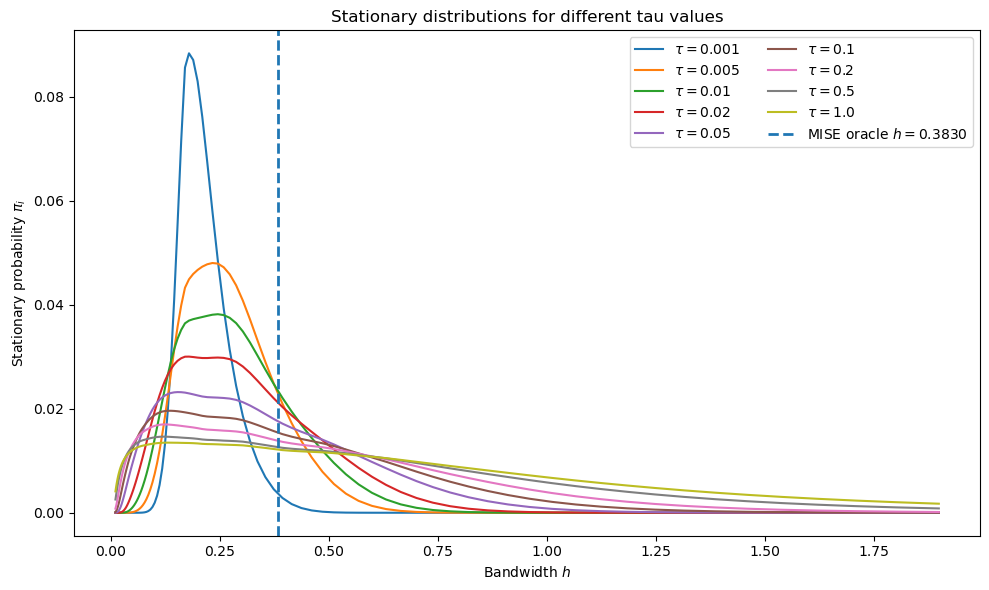

In [11]:
tau_values = [
    0.001,
    0.005,
    0.01,
    0.02,
    0.05,
    0.1,
    0.2,
    0.5,
    1.0,
]

selected_bandwidths = []

plt.figure(figsize=(10, 6))

for tau in tau_values:
    try:
        result = doob_transform_from_divergence_safe(
            divergence_matrix=kl_matrix_mc,
            tau=tau,
            remove_diagonal=False,
        )

        pi = result["stationary_distribution"]

        selected_index = int(np.argmax(pi))
        selected_h = float(bandwidths[selected_index])

        selected_bandwidths.append(selected_h)

        minimum_similarity = result[
            "minimum_off_diagonal_similarity"
        ]

        print(
            f"tau={tau:.4g}, "
            f"selected h={selected_h:.6f}, "
            f"minimum off-diagonal similarity="
            f"{minimum_similarity:.3e}"
        )

        plt.plot(
            bandwidths,
            pi,
            label=rf"$\tau={tau}$",
        )

    except (RuntimeError, FloatingPointError) as error:
        selected_bandwidths.append(np.nan)

        print(
            f"tau={tau:.4g} skipped: {error}"
        )

plt.axvline(
    h_oracle,
    linestyle="--",
    linewidth=2,
    label=rf"MISE oracle $h={h_oracle:.4f}$",
)

plt.xlabel(r"Bandwidth $h$")
plt.ylabel(r"Stationary probability $\pi_i$")
plt.title("Stationary distributions for different tau values")
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

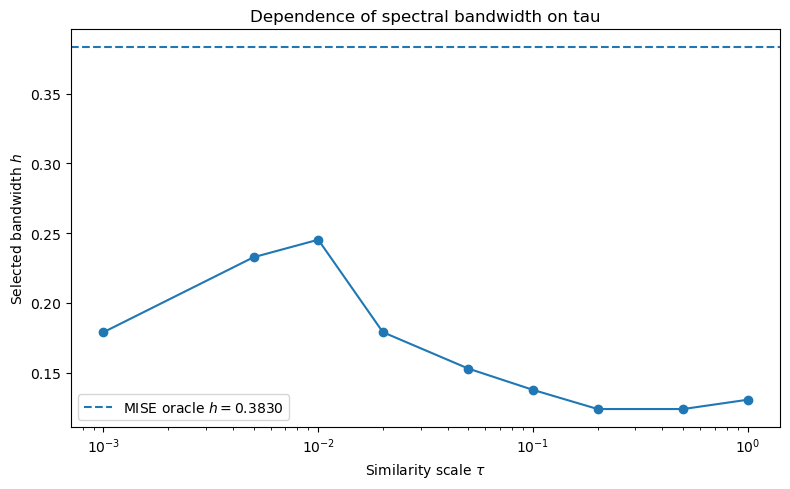

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    tau_values,
    selected_bandwidths,
    marker="o",
)

plt.axhline(
    h_oracle,
    linestyle="--",
    label=rf"MISE oracle $h={h_oracle:.4f}$",
)

plt.xscale("log")
plt.xlabel(r"Similarity scale $\tau$")
plt.ylabel(r"Selected bandwidth $h$")
plt.title("Dependence of spectral bandwidth on tau")
plt.legend()
plt.tight_layout()
plt.show()